# Bank Marketing Subscription Prediction – Decision Tree

### This project uses a Decision Tree Classifier to predict whether a customer will subscribe to a bank term deposit.

### The model is trained on the Bank Marketing dataset using Scikit-learn.

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier

## Load Dataset

In [2]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd

data = fetch_ucirepo(id=222)

df = pd.concat([
    data.data.features,
    data.data.targets
], axis=1)

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


## Select Features (X)

In [3]:
X = df[['age', 'job', 'marital', 'education',
        'default', 'balance', 'housing', 'loan',
        'contact', 'day_of_week', 'month', 'duration',
        'campaign', 'pdays', 'previous', 'poutcome']].values

X[0:5]

array([[58, 'management', 'married', 'tertiary', 'no', 2143, 'yes', 'no',
        nan, 5, 'may', 261, 1, -1, 0, nan],
       [44, 'technician', 'single', 'secondary', 'no', 29, 'yes', 'no',
        nan, 5, 'may', 151, 1, -1, 0, nan],
       [33, 'entrepreneur', 'married', 'secondary', 'no', 2, 'yes',
        'yes', nan, 5, 'may', 76, 1, -1, 0, nan],
       [47, 'blue-collar', 'married', nan, 'no', 1506, 'yes', 'no', nan,
        5, 'may', 92, 1, -1, 0, nan],
       [33, nan, 'single', nan, 'no', 1, 'no', 'no', nan, 5, 'may', 198,
        1, -1, 0, nan]], dtype=object)

## Select Feature (y)

In [4]:
y = df['y']

## Encode Categorical Features

In [5]:
from sklearn import preprocessing
import numpy as np
import pandas as pd

# job - column 1
le_job = preprocessing.LabelEncoder()
X[:,1] = pd.Series(X[:,1]).fillna('missing')
le_job.fit(X[:,1])
X[:,1] = le_job.transform(X[:,1])


# marital - column 2
le_marital = preprocessing.LabelEncoder()
le_marital.fit(X[:,2])
X[:,2] = le_marital.transform(X[:,2])


# education - column 3
le_edu = preprocessing.LabelEncoder()
X[:,3] = pd.Series(X[:,3]).fillna('missing')
le_edu.fit(X[:,3])
X[:,3] = le_edu.transform(X[:,3])


# default - column 4
le_default = preprocessing.LabelEncoder()
le_default.fit(X[:,4])
X[:,4] = le_default.transform(X[:,4])


# housing - column 6
le_housing = preprocessing.LabelEncoder()
le_housing.fit(X[:,6])
X[:,6] = le_housing.transform(X[:,6])


# loan - column 7
le_loan = preprocessing.LabelEncoder()
le_loan.fit(X[:,7])
X[:,7] = le_loan.transform(X[:,7])


# contact - column 8
le_contact = preprocessing.LabelEncoder()
X[:,8] = pd.Series(X[:,8]).fillna('missing')
le_contact.fit(X[:,8])
X[:,8] = le_contact.transform(X[:,8])


# month - column 10
le_month = preprocessing.LabelEncoder()
le_month.fit(X[:,10])
X[:,10] = le_month.transform(X[:,10])


# poutcome - column 15
le_poutcome = preprocessing.LabelEncoder()
X[:,15] = pd.Series(X[:,15]).fillna('missing')
le_poutcome.fit(X[:,15])
X[:,15] = le_poutcome.transform(X[:,15])
X[0:5]

array([[58, 4, 1, 3, 0, 2143, 1, 0, 1, 5, 8, 261, 1, -1, 0, 1],
       [44, 10, 2, 2, 0, 29, 1, 0, 1, 5, 8, 151, 1, -1, 0, 1],
       [33, 2, 1, 2, 0, 2, 1, 1, 1, 5, 8, 76, 1, -1, 0, 1],
       [47, 1, 1, 0, 0, 1506, 1, 0, 1, 5, 8, 92, 1, -1, 0, 1],
       [33, 5, 2, 0, 0, 1, 0, 0, 1, 5, 8, 198, 1, -1, 0, 1]], dtype=object)

## Encode Target Variable

In [6]:
le_y = preprocessing.LabelEncoder()
le_y.fit(['no', 'yes'])
y = le_y.transform(y)

## Import Train-Test Split

In [7]:
from sklearn.model_selection import train_test_split

## Split Training and Testing Data

In [8]:
X_trainset, X_testset, y_trainset, y_testset = train_test_split(
    X, y,
    test_size=0.3,
    random_state=3
)

## Build Decision Tree Model

In [9]:
from sklearn.tree import DecisionTreeClassifier 
banktree = DecisionTreeClassifier(criterion="entropy", max_depth = 4)
banktree

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

## Train Decision Tree Model

In [10]:
banktree.fit(X_trainset,y_trainset)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

## Make Predictions

In [11]:
predtree = banktree.predict(X_testset)
print (predtree [0:5])
print (y_testset [0:5])

[0 0 0 0 0]
[0 0 0 0 0]


## Evaluate Model Accuracy

In [12]:
from sklearn import metrics
import matplotlib.pyplot as plt

print("Decision Tree's Accuracy:",
      metrics.accuracy_score(y_testset, predtree))

Decision Tree's Accuracy: 0.9007667354762607


## Install Visualization Libraries

In [13]:
!conda install --override-channels -c conda-forge pydotplus graphviz python-graphviz -y

^C




==> WARNING: A newer version of conda exists. <==
    current version: 26.7.3
    latest version: 26.10.0

Please update conda by running

    $ conda self update




Jupyter detected...
Channels:
 - conda-forge
Platform: win-64
Solving environment: ...working... done

# All requested packages already installed.



## Visualize Decision Tree

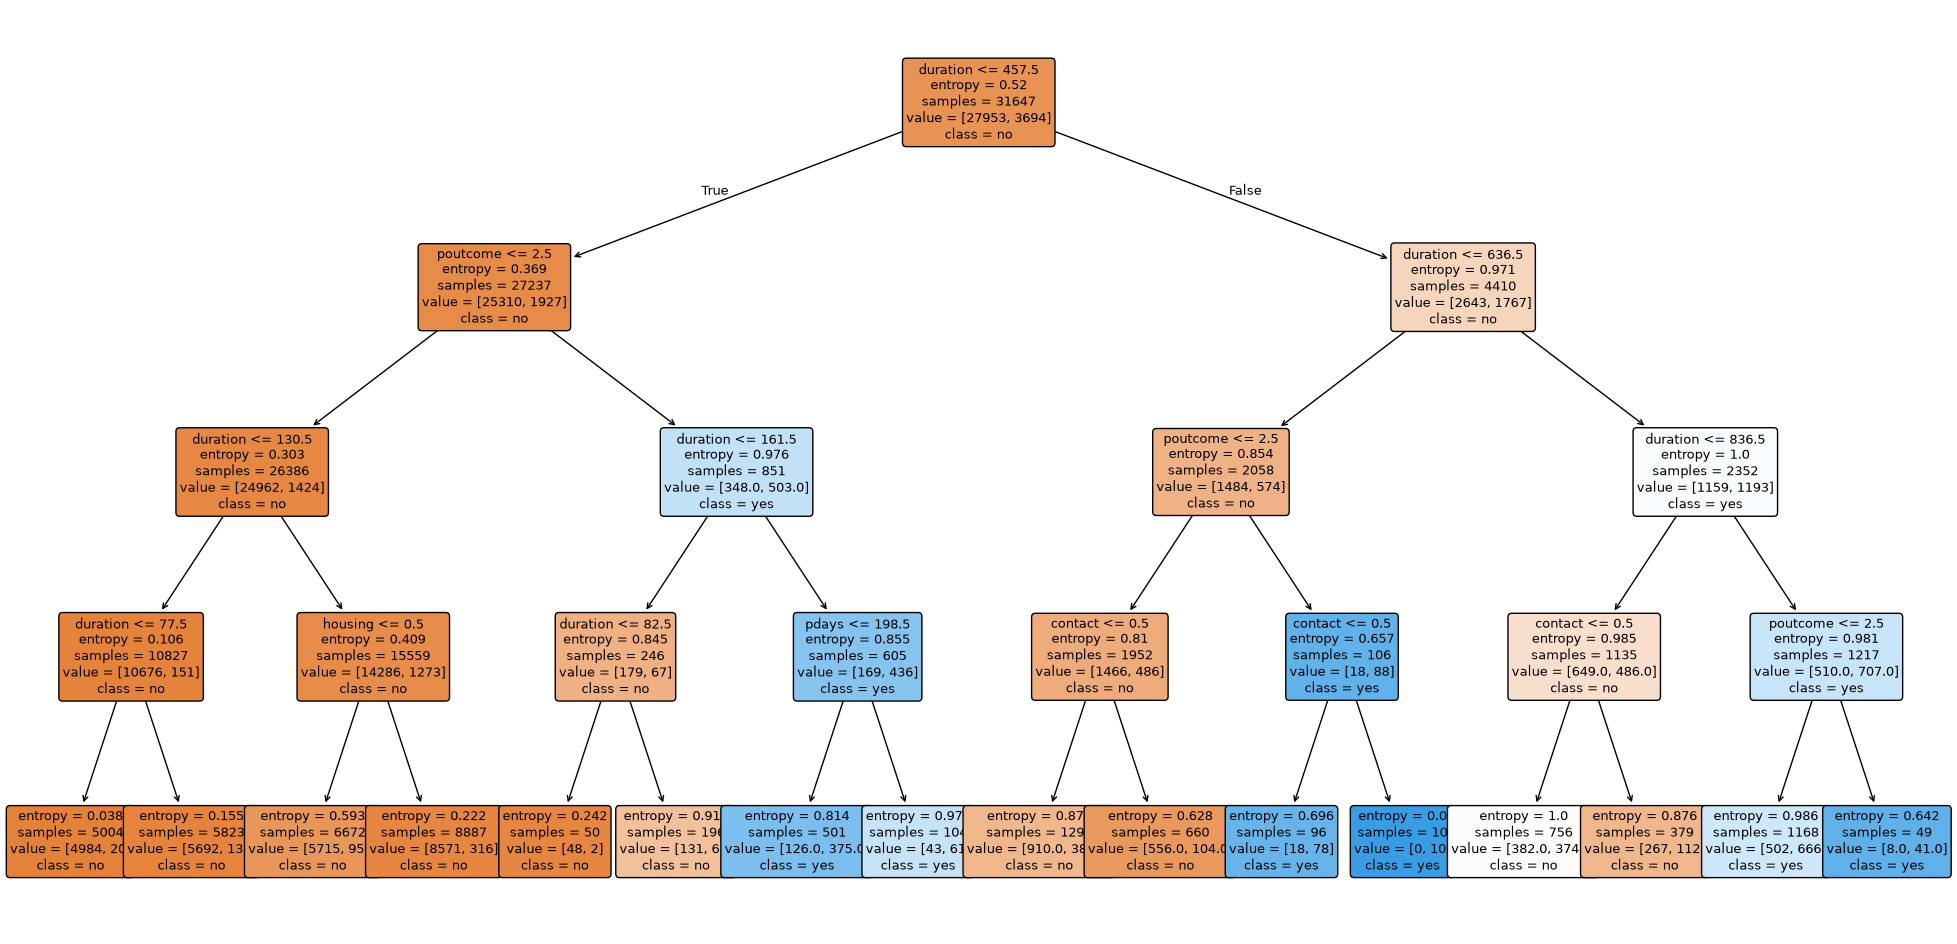

In [14]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(25, 12))

plot_tree(
    banktree,
    feature_names=df.drop('y', axis=1).columns,
    class_names=['no', 'yes'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.savefig('Decision_Tree.png', dpi=300, bbox_inches='tight')
plt.show()